In [1]:
import os, glob, time
import numpy as np
import cv2
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
from PIL import Image

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(DEVICE)

cuda


In [27]:
from google.colab import drive
drive.mount('/content/drive')

DRIVE       = "/content/drive/MyDrive"
SCENES_ROOT = f"{DRIVE}/Forest batch 1"          #shortcut, read only
DATA_ROOT   = f"{DRIVE}/drone-test"              #test set: hazy/ + GT/
OUT         = f"{DRIVE}/outputs_drone/dehazenet_v4"
CKPT        = f"{DRIVE}/checkpoints/dehazenet_v2.pth"

TRAIN_SCENES = ["01_night-moon_nadir-hover", "03_predawn_oblique-orbit", "04_sunrise_far-high-south",
                "05_morning_fast-pass-south", "07_afternoon_steep-push", "08_overcast_hover-southwest", "10_dusk_high-orbit"]
HAZY, CLEAR = "visible_haze", "visible_clear"

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


parameter

In [3]:
#training data
TRAIN_STEP = 5            #every 5th frame, ~400 pairs
LONG_SIDE = 512           #resize before caching in RAM
CROP = 256

#training
EPOCHS = 30
BATCH = 16
LR = 1e-3

#physics, same as DCP
A_PATCH = 15              #dark channel patch for A
A_TOP = 0.001             #brightest 0.1% of the dark channel
T_MIN = 0.1

#t refinement at inference (guided filter, as in the paper)
GF_RADIUS = 60
GF_EPS = 1e-3

training data

In [7]:
def load(p):
    img = Image.open(p).convert('RGB')
    s = LONG_SIDE / max(img.size)
    return np.asarray(img.resize((round(img.size[0] * s), round(img.size[1] * s)), Image.BICUBIC))

pairs = []
for scene in TRAIN_SCENES:
    hazy = sorted(glob.glob(f"{SCENES_ROOT}/{scene}/frames/{HAZY}/*"))[::TRAIN_STEP]
    gt   = sorted(glob.glob(f"{SCENES_ROOT}/{scene}/frames/{CLEAR}/*"))[::TRAIN_STEP]
    pairs += [(load(h), load(g)) for h, g in zip(hazy, gt)]
    print(scene, len(pairs))


class PairDataset(torch.utils.data.Dataset):
    #random crop + horizontal flip
    def __len__(self):
        return len(pairs)

    def __getitem__(self, i):
        hazy, gt = pairs[i]
        y = np.random.randint(0, hazy.shape[0] - CROP + 1)
        x = np.random.randint(0, hazy.shape[1] - CROP + 1)
        hazy, gt = hazy[y:y + CROP, x:x + CROP], gt[y:y + CROP, x:x + CROP]
        if np.random.rand() < 0.5:
            hazy, gt = hazy[:, ::-1], gt[:, ::-1]
        to_t = lambda a: torch.from_numpy(a.copy()).permute(2, 0, 1).float() / 255
        return to_t(hazy), to_t(gt)


loader = torch.utils.data.DataLoader(PairDataset(), batch_size=BATCH, shuffle=True, num_workers=2, drop_last=True)

01_night-moon_nadir-hover 60
03_predawn_oblique-orbit 132
04_sunrise_far-high-south 192
05_morning_fast-pass-south 228
07_afternoon_steep-push 282
08_overcast_hover-southwest 324
10_dusk_high-orbit 408


model

In [10]:
class DehazeNet(nn.Module):
    #t branch: same as v1. A branch: small conv -> global pool -> RGB, replaces the dark channel rule
    def __init__(self):
        super().__init__()
        self.f1 = nn.Conv2d(3, 16, 5, padding=2)
        self.f2 = nn.ModuleList([nn.Conv2d(4, 16, k, padding=k // 2) for k in (3, 5, 7)])
        self.f4 = nn.Conv2d(48, 1, 6)
        self.a_head = nn.Sequential(
            nn.Conv2d(3, 16, 3, stride=2, padding=1), nn.ReLU(),
            nn.Conv2d(16, 32, 3, stride=2, padding=1), nn.ReLU(),
            nn.AdaptiveAvgPool2d(1), nn.Flatten(),
            nn.Linear(32, 3), nn.Sigmoid())                       #A in [0, 1], (B, 3)

    def transmission(self, x):
        b, _, h, w = x.shape
        x = self.f1(x).view(b, 4, 4, h, w).max(dim=2)[0]          #maxout: 16 -> 4 maps
        x = torch.cat([conv(x) for conv in self.f2], dim=1)        #3x3, 5x5, 7x7 -> 48 maps
        x = F.max_pool2d(x, 7, stride=1, padding=3)                #local extremum
        x = self.f4(F.pad(x, (2, 3, 2, 3)))                        #6x6 conv, padded to keep size
        # return x.clamp(0, 1)                                       #BReLU -> t in [0, 1]
        return torch.sigmoid(x)                                    #smooth, gradient never exactly zero

    def forward(self, x):
        return self.transmission(x), self.a_head(x)


def recover(I, t, A):
    A = A[:, :, None, None]
    return ((I - A) / t.clamp(min=T_MIN) + A).clamp(0, 1)          #invert I = J*t + A*(1-t)


# net = DehazeNet().to(DEVICE)
# print(f"{sum(p.numel() for p in net.parameters())} params")
net = DehazeNet().to(DEVICE)
nn.init.constant_(net.a_head[-2].bias, 2.0)                        #A starts near sigmoid(2) = 0.88, like a bright airlight
print(f"{sum(p.numel() for p in net.parameters())} params")

13492 params


In [11]:
net.load_state_dict(torch.load(CKPT))

<All keys matched successfully>

train

In [ ]:
opt = torch.optim.Adam(net.parameters(), lr=LR)
sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, EPOCHS)

for epoch in range(EPOCHS):
    net.train()
    total = 0
    for hazy, gt in loader:
        hazy, gt = hazy.to(DEVICE), gt.to(DEVICE)
        t, A = net(hazy)
        J = recover(hazy, t, A)
        loss = F.l1_loss(J, gt)
        opt.zero_grad(); loss.backward(); opt.step()
        total += loss.item()
    sched.step()
    print(f"epoch {epoch + 1}/{EPOCHS} | L1 {total / len(loader):.4f}")

os.makedirs(os.path.dirname(CKPT), exist_ok=True)
torch.save(net.state_dict(), CKPT)

inference

In [20]:
def guided_filter(guide, src, r=GF_RADIUS, eps=GF_EPS):
    #edge-preserving smoothing of src, following the edges of guide (He et al., 2010)
    box = lambda x: cv2.boxFilter(x, -1, (2 * r + 1, 2 * r + 1))
    mean_I, mean_p = box(guide), box(src)
    a = (box(guide * src) - mean_I * mean_p) / (box(guide * guide) - mean_I * mean_I + eps)
    b = mean_p - a * mean_I
    return box(a) * guide + box(b)


@torch.no_grad()
def dehaze_full(rgb):
    #t and A estimated at the training scale (long side LONG_SIDE), t upsampled with the guided filter
    net.eval()
    I = torch.from_numpy(rgb.copy()).permute(2, 0, 1)[None].float().div(255).to(DEVICE)
    H, W = I.shape[2:]
    t_small, A = net(F.interpolate(I, scale_factor=LONG_SIDE / max(H, W), mode='bilinear'))
    t = F.interpolate(t_small, size=(H, W), mode='bilinear')[0, 0].cpu().numpy()
    t = guided_filter(cv2.cvtColor(rgb, cv2.COLOR_RGB2GRAY).astype(np.float32) / 255, t)
    J = recover(I, torch.from_numpy(t).to(DEVICE)[None, None], A)
    return (J[0].permute(1, 2, 0).cpu().numpy() * 255 + 0.5).astype(np.uint8), t


def dehaze(hazy):
    #hazy: PIL RGB image -> uint8 RGB array
    return dehaze_full(np.asarray(hazy))[0]

In [21]:
#guided filter radius sweep for v4 and oracle t, no retraining
RADII = [30, 15, 5]
hazy_paths = sorted(glob.glob(f"{DATA_ROOT}/hazy/*"))
gt_paths = sorted(glob.glob(f"{DATA_ROOT}/GT/*"))
for r in RADII:
    for name in (f"v4_r{r}", f"oracle_r{r}"):
        os.makedirs(f"{DRIVE}/outputs_drone/{name}", exist_ok=True)

def save(J, name, p):
    Image.fromarray((J[0].permute(1, 2, 0).cpu().numpy() * 255 + 0.5).astype(np.uint8)).save(f"{DRIVE}/outputs_drone/{name}/{os.path.basename(p)}")

for hp, gp in zip(hazy_paths, gt_paths):
    rgb = np.asarray(Image.open(hp).convert('RGB'))
    gray = cv2.cvtColor(rgb, cv2.COLOR_RGB2GRAY).astype(np.float32) / 255
    I = torch.from_numpy(rgb.copy()).permute(2, 0, 1)[None].float().div(255).to(DEVICE)
    J = torch.from_numpy(np.asarray(Image.open(gp).convert('RGB')).copy()).permute(2, 0, 1)[None].float().div(255).to(DEVICE)
    H, W = I.shape[2:]
    with torch.no_grad():
        net.eval()
        t_small, A = net(F.interpolate(I, scale_factor=LONG_SIDE / max(H, W), mode='bilinear'))
        t_v4 = F.interpolate(t_small, size=(H, W), mode='bilinear')[0, 0].cpu().numpy()
        a = A[:, :, None, None]
        t_or = (((I - a) * (J - a)).sum(1, keepdim=True) / ((J - a) ** 2).sum(1, keepdim=True).clamp(min=1e-6)).clamp(T_MIN, 1)[0, 0].cpu().numpy()
    for r in RADII:
        for name, t in ((f"v4_r{r}", t_v4), (f"oracle_r{r}", t_or)):
            tt = guided_filter(gray, t, r=r)
            save(recover(I, torch.from_numpy(tt).to(DEVICE)[None, None], A), name, hp)
    print(os.path.basename(hp))

02_night-dark_low-trunks-north_0001.png
02_night-dark_low-trunks-north_0018.png
02_night-dark_low-trunks-north_0035.png
02_night-dark_low-trunks-north_0052.png
02_night-dark_low-trunks-north_0069.png
02_night-dark_low-trunks-north_0086.png
02_night-dark_low-trunks-north_0103.png
02_night-dark_low-trunks-north_0120.png
02_night-dark_low-trunks-north_0137.png
02_night-dark_low-trunks-north_0154.png
02_night-dark_low-trunks-north_0171.png
02_night-dark_low-trunks-north_0188.png
02_night-dark_low-trunks-north_0205.png
02_night-dark_low-trunks-north_0222.png
02_night-dark_low-trunks-north_0240.png
06_midday_nadir-rotate_0001.png
06_midday_nadir-rotate_0015.png
06_midday_nadir-rotate_0030.png
06_midday_nadir-rotate_0045.png
06_midday_nadir-rotate_0060.png
06_midday_nadir-rotate_0075.png
06_midday_nadir-rotate_0090.png
06_midday_nadir-rotate_0105.png
06_midday_nadir-rotate_0120.png
06_midday_nadir-rotate_0135.png
06_midday_nadir-rotate_0150.png
06_midday_nadir-rotate_0165.png
06_midday_nadir-

preview a single image

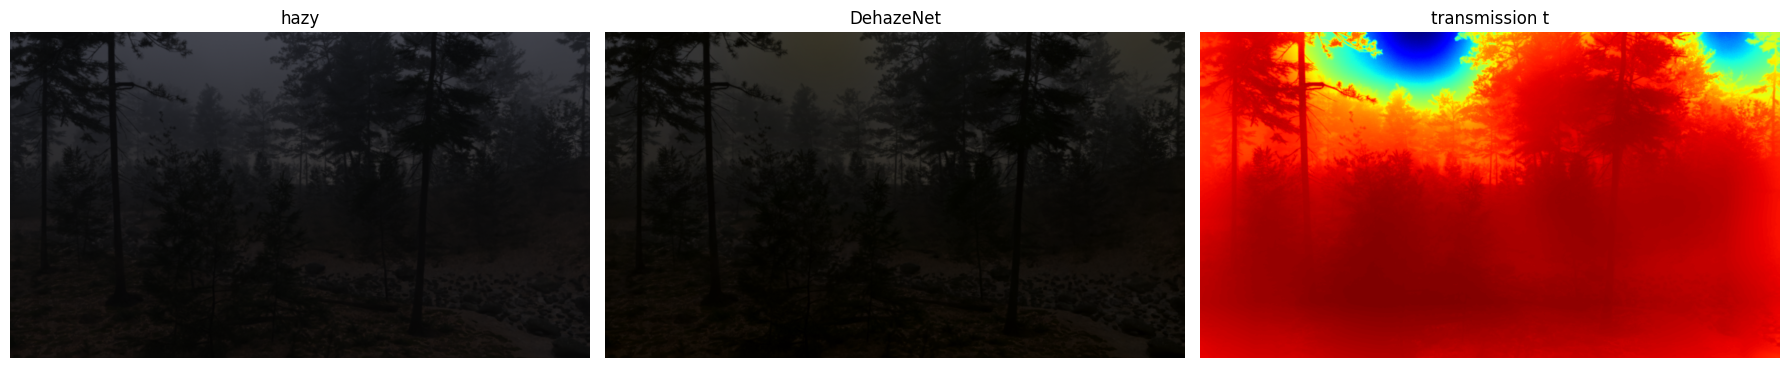

In [22]:
hazy_paths = sorted(glob.glob(f"{DATA_ROOT}/hazy/*"))
os.makedirs(OUT, exist_ok=True)

hazy = np.asarray(Image.open(hazy_paths[0]).convert('RGB'))
J, t = dehaze_full(hazy)
fig, ax = plt.subplots(1, 3, figsize=(18, 5))
for a, im, title, cmap in zip(ax, [hazy, J, t], ['hazy', 'DehazeNet', 'transmission t'], [None, None, 'jet']):
    a.imshow(im, cmap=cmap); a.set_title(title); a.axis('off')
plt.tight_layout(); plt.show()

run over the test set

In [23]:
for p in hazy_paths:
    hazy = Image.open(p).convert('RGB')
    t0 = time.time()
    pred = dehaze(hazy)
    dt = time.time() - t0
    Image.fromarray(pred).save(f"{OUT}/{os.path.basename(p)}")
    print(f"{os.path.basename(p)} | {hazy.size[0]}x{hazy.size[1]} | {dt:.2f}s")

02_night-dark_low-trunks-north_0001.png | 1280x720 | 0.07s
02_night-dark_low-trunks-north_0018.png | 1280x720 | 0.06s
02_night-dark_low-trunks-north_0035.png | 1280x720 | 0.07s
02_night-dark_low-trunks-north_0052.png | 1280x720 | 0.06s
02_night-dark_low-trunks-north_0069.png | 1280x720 | 0.06s
02_night-dark_low-trunks-north_0086.png | 1280x720 | 0.07s
02_night-dark_low-trunks-north_0103.png | 1280x720 | 0.06s
02_night-dark_low-trunks-north_0120.png | 1280x720 | 0.07s
02_night-dark_low-trunks-north_0137.png | 1280x720 | 0.06s
02_night-dark_low-trunks-north_0154.png | 1280x720 | 0.07s
02_night-dark_low-trunks-north_0171.png | 1280x720 | 0.06s
02_night-dark_low-trunks-north_0188.png | 1280x720 | 0.06s
02_night-dark_low-trunks-north_0205.png | 1280x720 | 0.06s
02_night-dark_low-trunks-north_0222.png | 1280x720 | 0.06s
02_night-dark_low-trunks-north_0240.png | 1280x720 | 0.06s
06_midday_nadir-rotate_0001.png | 1280x720 | 0.06s
06_midday_nadir-rotate_0015.png | 1280x720 | 0.06s
06_midday_nad

oraclet

In [24]:
#oracle t: best possible t per pixel given GT and the learned A -> upper bound of the scattering model
for name in ("oracle_t", "oracle_t_gf"):
    os.makedirs(f"{DRIVE}/outputs_drone/{name}", exist_ok=True)

gt_paths = sorted(glob.glob(f"{DATA_ROOT}/GT/*"))
for hp, gp in zip(hazy_paths, gt_paths):
    rgb = np.asarray(Image.open(hp).convert('RGB'))
    I = torch.from_numpy(rgb.copy()).permute(2, 0, 1)[None].float().div(255).to(DEVICE)
    J = torch.from_numpy(np.asarray(Image.open(gp).convert('RGB')).copy()).permute(2, 0, 1)[None].float().div(255).to(DEVICE)
    with torch.no_grad():
        _, A = net(F.interpolate(I, scale_factor=LONG_SIDE / max(I.shape[2:]), mode='bilinear'))
        a = A[:, :, None, None]
        #least squares over RGB: t = sum (I-A)(J-A) / sum (J-A)^2
        t = ((I - a) * (J - a)).sum(1, keepdim=True) / ((J - a) ** 2).sum(1, keepdim=True).clamp(min=1e-6)
        t = t.clamp(T_MIN, 1)
    t_raw = t[0, 0].cpu().numpy()
    t_gf = guided_filter(cv2.cvtColor(rgb, cv2.COLOR_RGB2GRAY).astype(np.float32) / 255, t_raw)
    for name, tt in (("oracle_t", t_raw), ("oracle_t_gf", t_gf)):
        out = recover(I, torch.from_numpy(tt).to(DEVICE)[None, None], A)
        Image.fromarray((out[0].permute(1, 2, 0).cpu().numpy() * 255 + 0.5).astype(np.uint8)).save(f"{DRIVE}/outputs_drone/{name}/{os.path.basename(hp)}")
    print(os.path.basename(hp))

02_night-dark_low-trunks-north_0001.png
02_night-dark_low-trunks-north_0018.png
02_night-dark_low-trunks-north_0035.png
02_night-dark_low-trunks-north_0052.png
02_night-dark_low-trunks-north_0069.png
02_night-dark_low-trunks-north_0086.png
02_night-dark_low-trunks-north_0103.png
02_night-dark_low-trunks-north_0120.png
02_night-dark_low-trunks-north_0137.png
02_night-dark_low-trunks-north_0154.png
02_night-dark_low-trunks-north_0171.png
02_night-dark_low-trunks-north_0188.png
02_night-dark_low-trunks-north_0205.png
02_night-dark_low-trunks-north_0222.png
02_night-dark_low-trunks-north_0240.png
06_midday_nadir-rotate_0001.png
06_midday_nadir-rotate_0015.png
06_midday_nadir-rotate_0030.png
06_midday_nadir-rotate_0045.png
06_midday_nadir-rotate_0060.png
06_midday_nadir-rotate_0075.png
06_midday_nadir-rotate_0090.png
06_midday_nadir-rotate_0105.png
06_midday_nadir-rotate_0120.png
06_midday_nadir-rotate_0135.png
06_midday_nadir-rotate_0150.png
06_midday_nadir-rotate_0165.png
06_midday_nadir-

evaluate

In [25]:
!pip install -q pyiqa
!rm -rf /content/vx
!git clone -q --depth 1 https://github.com/fahimrayhan/vidhance-extendview.git /content/vx

import sys
from pathlib import Path
sys.path.insert(0, "/content/vx/dehazing")
from evaluation import evaluate

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
Downloading: "https://download.pytorch.org/models/alexnet-owt-7be5be79.pth" to /root/.cache/torch/hub/checkpoints/alexnet-owt-7be5be79.pth


100%|██████████| 233M/233M [00:01<00:00, 230MB/s]


Downloading: "https://huggingface.co/chaofengc/IQA-PyTorch-Weights/resolve/main/LPIPS_v0.1_alex-df73285e.pth" to /root/.cache/torch/hub/pyiqa/LPIPS_v0.1_alex-df73285e.pth



100%|██████████| 5.87k/5.87k [00:00<00:00, 12.5kB/s]


Loading pretrained model LPIPS from /root/.cache/torch/hub/pyiqa/LPIPS_v0.1_alex-df73285e.pth
Downloading: "https://huggingface.co/chaofengc/IQA-PyTorch-Weights/resolve/main/niqe_modelparameters.mat" to /root/.cache/torch/hub/pyiqa/niqe_modelparameters.mat



100%|██████████| 8.15k/8.15k [00:00<00:00, 23.1MB/s]


Downloading: "https://huggingface.co/chaofengc/IQA-PyTorch-Weights/resolve/main/brisque_svm_weights.pth" to /root/.cache/torch/hub/pyiqa/brisque_svm_weights.pth



100%|██████████| 112k/112k [00:00<00:00, 290kB/s]


In [26]:
OUTPUTS = Path(f"{DRIVE}/outputs_drone")
methods = {p.name: str(p) for p in sorted(OUTPUTS.iterdir()) if p.is_dir()}
print(len(methods), "methods:", list(methods))

per_image, summary = evaluate(DATA_ROOT, methods)
summary.to_csv(OUTPUTS / f"summary_{len(methods)}methods.csv")
per_image.to_csv(OUTPUTS / f"per_image_{len(methods)}methods.csv", index=False)
summary

14 methods: ['cap', 'dcp', 'dehazenet', 'dehazenet_v2', 'dehazenet_v3', 'dehazenet_v4', 'oracle_r15', 'oracle_r30', 'oracle_r5', 'oracle_t', 'oracle_t_gf', 'v4_r15', 'v4_r30', 'v4_r5']
[1/45] 02_night-dark_low-trunks-north_0001.png
[2/45] 02_night-dark_low-trunks-north_0018.png
[3/45] 02_night-dark_low-trunks-north_0035.png
[4/45] 02_night-dark_low-trunks-north_0052.png
[5/45] 02_night-dark_low-trunks-north_0069.png
[6/45] 02_night-dark_low-trunks-north_0086.png
[7/45] 02_night-dark_low-trunks-north_0103.png
[8/45] 02_night-dark_low-trunks-north_0120.png
[9/45] 02_night-dark_low-trunks-north_0137.png
[10/45] 02_night-dark_low-trunks-north_0154.png
[11/45] 02_night-dark_low-trunks-north_0171.png
[12/45] 02_night-dark_low-trunks-north_0188.png
[13/45] 02_night-dark_low-trunks-north_0205.png
[14/45] 02_night-dark_low-trunks-north_0222.png
[15/45] 02_night-dark_low-trunks-north_0240.png
[16/45] 06_midday_nadir-rotate_0001.png
[17/45] 06_midday_nadir-rotate_0015.png
[18/45] 06_midday_nadir-

/content/vx/dehazing/evaluation/metrics.py:71: RuntimeWarning: invalid value encountered in scalar divide
  return (n_r - n_o) / n_o
/usr/local/lib/python3.13/dist-packages/numpy/_core/fromnumeric.py:3824: RuntimeWarning: Mean of empty slice
  return _methods._mean(a, axis=axis, dtype=dtype,
/usr/local/lib/python3.13/dist-packages/numpy/_core/_methods.py:142: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)
/content/vx/dehazing/evaluation/metrics.py:71: RuntimeWarning: divide by zero encountered in scalar divide
  return (n_r - n_o) / n_o


[35/45] 09_golden_far-west-pullback_0095.png
[36/45] 09_golden_far-west-pullback_0118.png
[37/45] 09_golden_far-west-pullback_0142.png
[38/45] 09_golden_far-west-pullback_0165.png
[39/45] 09_golden_far-west-pullback_0189.png
[40/45] 09_golden_far-west-pullback_0212.png
[41/45] 09_golden_far-west-pullback_0236.png
[42/45] 09_golden_far-west-pullback_0259.png
[43/45] 09_golden_far-west-pullback_0283.png
[44/45] 09_golden_far-west-pullback_0306.png
[45/45] 09_golden_far-west-pullback_0330.png


,psnr,ssim,ciede2000,lpips,niqe,brisque,e,r,sigma
method,,,,,,,,,
hazy,17.002193,0.533179,12.078818,0.605954,5.779352,32.916522,0.0,1.000000,0.000000e+00
cap,17.097888,0.513376,13.029050,0.559250,5.306709,29.673675,inf,1.326572,2.007383e-02
dcp,13.365166,0.431690,19.871280,0.617796,5.127529,28.867813,inf,1.936661,5.489487e-04
dehazenet,14.942730,0.299513,15.282162,0.686533,5.370756,42.526029,inf,1.646932,2.850764e-01
dehazenet_v2,17.103253,0.519851,10.486510,0.602338,5.603040,31.367864,inf,1.105385,4.629147e-04
dehazenet_v3,16.994200,0.484863,10.755717,0.610873,5.521217,31.350582,inf,1.141817,1.855782e-02
dehazenet_v4,17.157450,0.519751,10.446256,0.600114,5.589133,31.332526,inf,1.107944,9.719088e-04
oracle_r15,18.783309,0.576199,9.633012,0.613029,5.504388,30.175780,inf,1.172955,3.014082e-05
oracle_r30,18.644787,0.572290,9.662919,0.602426,5.414816,30.547446,inf,1.177223,3.144290e-05
